In [1]:
import sys
print("Python path:", sys.executable)
print("Python version:", sys.version)



Python path: C:\Users\srisr\anaconda3\envs\drug_env2\python.exe
Python version: 3.9.25 (main, Nov  3 2025, 22:44:01) [MSC v.1929 64 bit (AMD64)]


In [2]:
import rdkit
import tensorflow as tf
from DeepPurpose import dataset
from DeepPurpose import utils
from DeepPurpose import DTI as models

print("All imports successful!")



All imports successful!


In [3]:

X_drugs, X_targets, y = dataset.load_process_DAVIS(path='./data')

print("Number of samples:", len(y))
print("First drug sample:", X_drugs[0])
print("First target sample:", X_targets[0])
print("First binding score:", y[0])


Beginning Processing...
100% [............................................................................] 179878 / 179878Beginning to extract zip file...
Default set to logspace (nM -> p) for easier regression
Done!
Number of samples: 30056
First drug sample: CC1=C2C=C(C=CC2=NN1)C3=CC(=CN=C3)OCC(CC4=CC=CC=C4)N
First target sample: MKKFFDSRREQGGSGLGSGSSGGGGSTSGLGSGYIGRVFGIGRQQVTVDEVLAEGGFAIVFLVRTSNGMKCALKRMFVNNEHDLQVCKREIQIMRDLSGHKNIVGYIDSSINNVSSGDVWEVLILMDFCRGGQVVNLMNQRLQTGFTENEVLQIFCDTCEAVARLHQCKTPIIHRDLKVENILLHDRGHYVLCDFGSATNKFQNPQTEGVNAVEDEIKKYTTLSYRAPEMVNLYSGKIITTKADIWALGCLLYKLCYFTLPFGESQVAICDGNFTIPDNSRYSQDMHCLIRYMLEPDPDKRPDIYQVSYFSFKLLKKECPIPNVQNSPIPAKLPEPVKASEAAAKKTQPKARLTDPIPTTETSIAPRQRPKAGQTQPNPGILPIQPALTPRKRATVQPPPQAAGSSNQPGLLASVPQPKPQAPPSQPLPQTQAKQPQAPPTPQQTPSTQAQGLPAQAQATPQHQQQLFLKQQQQQQQPPPAQQQPAGTFYQQQQAQTQQFQAVHPATQKPAIAQFPVVSQGGSQQQLMQNFYQQQQQQQQQQQQQQLATALHQQQLMTQQAALQQKPTMAAGQQPQPQPAAAPQPAPAQEPAIQAPVRQQPKVQTTPPPAVQGQKVGSLTPPSSPKTQRAGHRRILSDVTHSAVFGVPASKSTQLLQAAAAEASL

In [4]:
drug_encoding = 'CNN'
target_encoding = 'CNN'

train_data = utils.data_process(
    X_drugs, 
    X_targets, 
    y, 
    drug_encoding, 
    target_encoding, 
    split_method='random',
    frac=[0.8, 0.1, 0.1]
)

print("Data preprocessing done.")

Drug Target Interaction Prediction Mode...
in total: 30056 drug-target pairs
encoding drug...
unique drugs: 68
encoding protein...
unique target sequence: 379
splitting dataset...
Done.
Data preprocessing done.


In [5]:
X_drugs = X_drugs[:8000]
X_targets = X_targets[:8000]
y = y[:8000]

print("Reduced dataset size:", len(y))


Reduced dataset size: 8000


In [6]:
train, val, test = utils.data_process(
    X_drugs,
    X_targets,
    y,
    drug_encoding='CNN',
    target_encoding='CNN',
    split_method='random',
    frac=[0.7, 0.1, 0.2]
)

print("Data split done successfully.")


Drug Target Interaction Prediction Mode...
in total: 8000 drug-target pairs
encoding drug...
unique drugs: 19
encoding protein...
unique target sequence: 379
splitting dataset...
Done.
Data split done successfully.


In [7]:
# ===============================
# Deep Ensemble - Model 1
# ===============================
config = utils.generate_config(
    drug_encoding='CNN',
    target_encoding='CNN',
    train_epoch=10,          # reduced for faster training
    batch_size=64,         # faster
    LR=0.001,
    hidden_dim_drug=64,     # reduced
    hidden_dim_protein=64   # reduced
)

model = models.model_initialize(**config)

print("Model initialized successfully.")


Model initialized successfully.


In [ ]:
model.train(train, val, test)


In [9]:
model.save_model('./saved_model')

print("Model saved successfully!")


Model saved successfully!


In [ ]:
# ===============================
# Deep Ensemble - Model 2
# ===============================

config2 = utils.generate_config(
    drug_encoding='CNN',
    target_encoding='CNN',
    train_epoch=10,
    batch_size=64,
    LR=0.0005,   # Changed learning rate
    hidden_dim_drug=64,
    hidden_dim_protein=64
)

model2 = models.model_initialize(**config2)
print("Model 2 initialized successfully.")

model2.train(train, val, test)

model2.save_model('./saved_model2')
print("Model 2 saved successfully!")

Model 3 initialized successfully.
Let's use CPU/s!
--- Data Preparation ---
--- Go for Training ---
Training at Epoch 1 iteration 0 with loss 28.2539. Total time 0.0 hours
Training at Epoch 1 iteration 100 with loss 0.58142. Total time 0.02416 hours
Validation at Epoch 1 with loss:0.15175, MSE: 0.80138 , Pearson Correlation: 0.43718 with p-value: 1.13E-38 , Concordance Index: 0.75922
Training at Epoch 2 iteration 0 with loss 1.13648. Total time 0.0475 hours
Training at Epoch 2 iteration 100 with loss 0.58226. Total time 0.07166 hours
Validation at Epoch 2 with loss:1.32211, MSE: 0.68381 , Pearson Correlation: 0.51257 with p-value: 8.34E-55 , Concordance Index: 0.76739
Training at Epoch 3 iteration 0 with loss 0.51719. Total time 0.09055 hours
Training at Epoch 3 iteration 100 with loss 0.23137. Total time 0.11888 hours
Validation at Epoch 3 with loss:0.76177, MSE: 0.65588 , Pearson Correlation: 0.52957 with p-value: 4.92E-59 , Concordance Index: 0.78539
Training at Epoch 4 iteration 0 

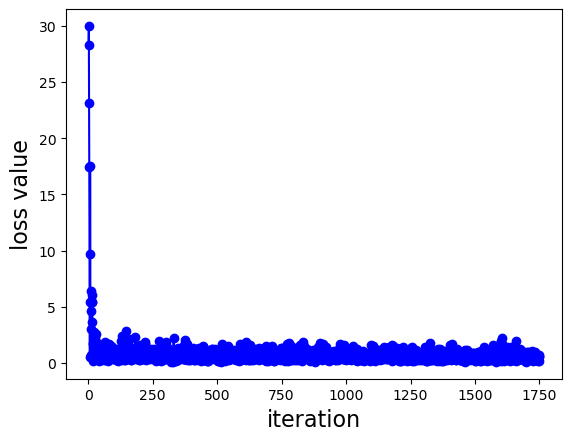

In [15]:
# ===============================
# Deep Ensemble - Model 3
# ===============================

config3 = utils.generate_config(
    drug_encoding='CNN',
    target_encoding='CNN',
    train_epoch=10,
    batch_size=32,        # Changed batch size
    LR=0.001,
    hidden_dim_drug=128,  # Increased capacity
    hidden_dim_protein=128
)

model3 = models.model_initialize(**config3)
print("Model 3 initialized successfully.")

model3.train(train, val, test)

model3.save_model('./saved_model3')
print("Model 3 saved successfully!")

In [8]:
# ===============================
# Load Trained Models
# ===============================

from DeepPurpose import DTI as models

model1_loaded = models.model_pretrained('./saved_model')
model2_loaded = models.model_pretrained('./saved_model2')
model3_loaded = models.model_pretrained('./saved_model3')

print("All models loaded successfully!")

All models loaded successfully!


In [9]:
# ===============================
# Get Predictions
# ===============================

pred1 = model1_loaded.predict(test)
pred2 = model2_loaded.predict(test)
pred3 = model3_loaded.predict(test)

print("Predictions generated from all models!")

predicting...
predicting...
predicting...
Predictions generated from all models!


In [10]:
# ===============================
# Ensemble Averaging
# ===============================

import numpy as np

ensemble_pred = (np.array(pred1) + np.array(pred2) + np.array(pred3)) / 3

print("Ensemble prediction generated successfully!")

Ensemble prediction generated successfully!


In [19]:
from sklearn.metrics import mean_squared_error
from scipy.stats import pearsonr
import numpy as np

true_values = np.array(test.Label)

mse = mean_squared_error(true_values, ensemble_pred)
pearson_corr, _ = pearsonr(true_values, ensemble_pred)

print("Ensemble MSE:", mse)
print("Ensemble Pearson Correlation:", pearson_corr)

Ensemble MSE: 0.44969576104243586
Ensemble Pearson Correlation: 0.6590559397831497


In [11]:
from blockchain import Blockchain

# Initialize blockchain
drug_chain = Blockchain()



In [12]:
from DeepPurpose import utils

def ensemble_predict_and_store(drug_smiles, disease_name, protein_sequence):

    X_drug = [drug_smiles]
    X_target = [protein_sequence]
    y_dummy = [0]

    drug_encoding = model1_loaded.config['drug_encoding']
    target_encoding = model1_loaded.config['target_encoding']

    test_data = utils.data_process(
        X_drug,
        X_target,
        y_dummy,
        drug_encoding=drug_encoding,
        target_encoding=target_encoding,
        split_method='no_split'
    )

    pred1 = model1_loaded.predict(test_data)[0]
    pred2 = model2_loaded.predict(test_data)[0]
    pred3 = model3_loaded.predict(test_data)[0]

    ensemble_score = float((pred1 + pred2 + pred3) / 3)

    prediction_data = {
        "drug": drug_smiles,
        "disease": disease_name,
        "ensemble_score": ensemble_score
    }

    block_hash = drug_chain.add_block(prediction_data)

    return ensemble_score, block_hash

In [13]:
unique_proteins = list(set(X_targets))
selected_proteins = unique_proteins[:10]

print("Selected proteins ready for UniProt mapping.")

Selected proteins ready for UniProt mapping.


In [14]:
print(selected_proteins[0])

MKIPNIGNVMNKFEILGVVGEGAYGVVLKCRHKETHEIVAIKKFKDSEENEEVKETTLRELKMLRTLKQENIVELKEAFRRRGKLYLVFEYVEKNMLELLEEMPNGVPPEKVKSYIYQLIKAIHWCHKNDIVHRDIKPENLLISHNDVLKLCDFGFARNLSEGNNANYTEYVATRWYRSPELLLGAPYGKSVDMWSVGCILGELSDGQPLFPGESEIDQLFTIQKVLGPLPSEQMKLFYSNPRFHGLRFPAVNHPQSLERRYLGILNSVLLDLMKNLLKLDPADRYLTEQCLNHPTFQTQRLLDRSPSRSAKRKPYHVESSTLSNRNQAGKSTALQSHHRSNSKDIQNLSVGLPRADEGLPANESFLNGNLAGASLSPLHTKTYQASSQPGSTSKDLTNNNIPHLLSPKEAKSKTEFDFNIDPKPSEGPGTKYLKSNSRSQQNRHSFMESSQSKAGTLQPNEKQSRHSYIDTIPQSSRSPSYRTKAKSHGALSDSKSVSNLSEARAQIAEPSTSRYFPSSCLDLNSPTSPTPTRHSDTRTLLSPSGRNNRNEGTLDSRRTTTRHSKTMEELKLPEHMDSSHSHSLSAPHESFSYGLGYTSPFSSQQRPHRHSMYVTRDKVRAKGLDGSLSIGQGMAARANSLQLLSPQPGEQLPPEMTVARSSVKETSREGTSSFHTRQKSEGGVYHDPHSDDGTAPKENRHLYNDPVPRRVGSFYRVPSPRPDNSFHENNVSTRVSSLPSESSSGTNHSKRQPAFDPWKSPENISHSEQLKEKEKQGFFRSMKKKKKKSQTVPNSDSPDLLTLQKSIHSASTPSSRPKEWRPEKISDLQTQSQPLKSLRKLLHLSSASNHPASSDPRFQPLTAQQTKNSFSEIRIHPLSQASGGSSNIRQEPAPKGRPALQLPDGGCDGRRQRHHSGPQDRRFMLRTTEQQGEYFCCGDPKKPHTPCVPNRALHRPISSPAPYPVLQVRGTSMCPTLQVRGTDAFSCPTQQSGFSFFVR

In [15]:
import requests

In [16]:
pip install requests

Note: you may need to restart the kernel to use updated packages.


Status: 200
{
  "IdentifierList": {
    "CID": [
      2244
    ]
  }
}



In [24]:
import requests

def get_smiles_from_pubchem(drug_name):
    
    # Step 1: Get CID
    cid_url = f"https://pubchem.ncbi.nlm.nih.gov/rest/pug/compound/name/{drug_name}/cids/JSON"
    cid_response = requests.get(cid_url)
    
    if cid_response.status_code != 200:
        print("Failed to fetch CID")
        return None
    
    try:
        cid_data = cid_response.json()
        cid = cid_data["IdentifierList"]["CID"][0]
    except:
        print("CID not found")
        return None
    
    # Step 2: Get SMILES
    smiles_url = f"https://pubchem.ncbi.nlm.nih.gov/rest/pug/compound/cid/{cid}/property/ConnectivitySMILES/JSON"
    smiles_response = requests.get(smiles_url)
    
    if smiles_response.status_code != 200:
        print("Failed to fetch SMILES")
        return None
    
    try:
        smiles_data = smiles_response.json()
        smiles = smiles_data["PropertyTable"]["Properties"][0]["ConnectivitySMILES"]
        return smiles
    except:
        print("SMILES not found")
        return None

In [25]:
import requests

def is_kinase_gene(gene_name):

    try:
        url = (
            f"https://rest.uniprot.org/uniprotkb/search?"
            f"query=gene:{gene_name}+AND+organism_id:9606+AND+keyword:KW-0418"
            f"&format=json"
        )

        response = requests.get(url, timeout=10)

        if response.status_code != 200:
            return False

        data = response.json()
        return len(data.get("results", [])) > 0

    except Exception:
        return False

In [26]:
def get_protein_sequence_from_uniprot(gene_name):
    url = f"https://rest.uniprot.org/uniprotkb/search?query=gene:{gene_name}+AND+organism_id:9606&format=fasta"
    response = requests.get(url)
    
    if response.status_code != 200:
        return None
    
    fasta_data = response.text
    lines = fasta_data.split("\n")
    
    sequence = ""
    for line in lines:
        if not line.startswith(">"):
            sequence += line.strip()
    
    return sequence

In [20]:
def full_real_prediction(drug_name, disease_name):
    
    print("Fetching SMILES from PubChem...")
    smiles = get_smiles_from_pubchem(drug_name)
    if not smiles:
        print("Drug not found.")
        return
    
    print("Fetching genes from DisGeNET...")
    genes = get_genes_from_disgenet(disease_name)
    
    if not genes:
        print("No genes found for disease.")
        return
    
    print("Filtering kinase genes...")
    kinase_genes = [gene for gene in genes if is_kinase_gene(gene)]
    
    if not kinase_genes:
        print("No kinase genes found for this disease.")
        return
    
    selected_gene = kinase_genes[0]
    print("Using kinase gene:", selected_gene)
    
    print("Fetching protein sequence from UniProt...")
    protein_seq = get_protein_sequence_from_uniprot(selected_gene)
    
    if not protein_seq:
        print("Protein sequence not found.")
        return
    
    print("Running ensemble prediction...")
    score, block_hash = ensemble_predict_and_store(
        smiles,
        disease_name,
        protein_seq
    )
    
    print("Prediction Score:", score)
    print("Stored in Blockchain with Hash:", block_hash)

In [27]:
print(get_smiles_from_pubchem("aspirin"))

CC(=O)OC1=CC=CC=C1C(=O)O


In [19]:
print(get_smiles_from_pubchem("Acetylsalicylic acid"))

CC(=O)OC1=CC=CC=C1C(=O)O


In [34]:
smiles_url = "https://pubchem.ncbi.nlm.nih.gov/rest/pug/compound/cid/2244/property/CanonicalSMILES/JSON"
response = requests.get(smiles_url)

print("Status:", response.status_code)
print(response.text)

Status: 200
{
  "PropertyTable": {
    "Properties": [
      {
        "CID": 2244,
        "ConnectivitySMILES": "CC(=O)OC1=CC=CC=C1C(=O)O"
      }
    ]
  }
}



In [35]:
import pandas as pd

ctd_df = pd.read_csv(
    r"C:\Users\srisr\Downloads\CTD_curated_genes_diseases.tsv.gz",
    sep="\t",
    compression="gzip",
    comment="#",     # ignore metadata lines
    header=None      # don't assume first row is header
)

print(ctd_df.head())
print(ctd_df.shape)

   0      1                          2             3                 4    5  \
0  A  50518                 Dermatitis  MESH:D003872  marker/mechanism  NaN   
1  A  50518          Diabetes Mellitus  MESH:D003920  marker/mechanism  NaN   
2  A  50518  Diabetes Mellitus, Type 2  MESH:D003924  marker/mechanism  NaN   
3  A  50518     Diabetic Nephropathies  MESH:D003928  marker/mechanism  NaN   
4  A  50518                      Edema  MESH:D004487  marker/mechanism  NaN   

                  6  
0          32937126  
1  1473152|25620042  
2           8146154  
3          37769864  
4          32937126  
(34247, 7)


In [36]:
ctd_df.columns = [
    "GeneSymbol",
    "GeneID",
    "DiseaseName",
    "DiseaseID",
    "DirectEvidence",
    "InferenceScore",
    "PubMedIDs"
]

ctd_df = ctd_df[["GeneSymbol", "DiseaseName"]]

ctd_df.head()

,GeneSymbol,DiseaseName
0,A,Dermatitis
1,A,Diabetes Mellitus
2,A,"Diabetes Mellitus, Type 2"
3,A,Diabetic Nephropathies
4,A,Edema


In [37]:
ctd_df[ctd_df["DiseaseName"].str.contains("colorectal", case=False)]

,GeneSymbol,DiseaseName
60,ABCA1,Colorectal Neoplasms
69,ABCA10,Colorectal Neoplasms
70,ABCA12,Colorectal Neoplasms
76,ABCA13,Colorectal Neoplasms
79,ABCA3,Colorectal Neoplasms
...,...,...
34151,ZNF292,Colorectal Neoplasms
34162,ZNF367,Colorectal Neoplasms
34176,ZNF432,Colorectal Neoplasms
34191,ZNF569,Colorectal Neoplasms


In [38]:
colorectal_genes = ctd_df[
    ctd_df["DiseaseName"] == "Colorectal Neoplasms"
]["GeneSymbol"].unique().tolist()

len(colorectal_genes)

300

In [39]:
print(type(X_targets))
print(len(X_targets))
print(X_targets[0])

<class 'numpy.ndarray'>
8000
MKKFFDSRREQGGSGLGSGSSGGGGSTSGLGSGYIGRVFGIGRQQVTVDEVLAEGGFAIVFLVRTSNGMKCALKRMFVNNEHDLQVCKREIQIMRDLSGHKNIVGYIDSSINNVSSGDVWEVLILMDFCRGGQVVNLMNQRLQTGFTENEVLQIFCDTCEAVARLHQCKTPIIHRDLKVENILLHDRGHYVLCDFGSATNKFQNPQTEGVNAVEDEIKKYTTLSYRAPEMVNLYSGKIITTKADIWALGCLLYKLCYFTLPFGESQVAICDGNFTIPDNSRYSQDMHCLIRYMLEPDPDKRPDIYQVSYFSFKLLKKECPIPNVQNSPIPAKLPEPVKASEAAAKKTQPKARLTDPIPTTETSIAPRQRPKAGQTQPNPGILPIQPALTPRKRATVQPPPQAAGSSNQPGLLASVPQPKPQAPPSQPLPQTQAKQPQAPPTPQQTPSTQAQGLPAQAQATPQHQQQLFLKQQQQQQQPPPAQQQPAGTFYQQQQAQTQQFQAVHPATQKPAIAQFPVVSQGGSQQQLMQNFYQQQQQQQQQQQQQQLATALHQQQLMTQQAALQQKPTMAAGQQPQPQPAAAPQPAPAQEPAIQAPVRQQPKVQTTPPPAVQGQKVGSLTPPSSPKTQRAGHRRILSDVTHSAVFGVPASKSTQLLQAAAAEASLNKSKSATTTPSGSPRTSQQNVYNPSEGSTWNPFDDDNFSKLTAEELLNKDFAKLGEGKHPEKLGGSAESLIPGFQSTQGDAFATTSFSAGTAEKRKGGQTVDSGLPLLSVSDPFIPLQVPDAPEKLIEGLKSPDTSLLLPDLLPMTDPFGSTSDAVIEKADVAVESLIPGLEPPVPQRLPSQTESVTSNRTDSLTGEDSLLDCSLLSNPTTDLLEEFAPTAISAPVHKAAEDSNLISGFDVPEGSDKVAEDEFDPIPVLITKNPQGGHSRNSSGSSESSLPNLARSLLLVDQLIDL


In [40]:
import pandas as pd

kinase_df = pd.read_csv(
    r"C:\Users\srisr\Downloads\uniprotkb_organism_id_9606_AND_keyword_2026_02_25.tsv.gz",
    sep="\t",
    compression="gzip"
)

print("Loaded UniProt kinases")
print(kinase_df.head())
print(kinase_df.shape)

Loaded UniProt kinases
        Entry    Reviewed        Entry Name  \
0  A0A090N7W4  unreviewed  A0A090N7W4_HUMAN   
1  A0A0S2Z310  unreviewed  A0A0S2Z310_HUMAN   
2  A0A0S2Z4D1  unreviewed  A0A0S2Z4D1_HUMAN   
3  A0A0S2Z4Q4  unreviewed  A0A0S2Z4Q4_HUMAN   
4  A0A0S2Z4Z8  unreviewed  A0A0S2Z4Z8_HUMAN   

                                       Protein names  \
0  Cyclin-dependent kinase 5 (Cell division prote...   
1  Serine/threonine-protein kinase receptor (EC 2...   
2  Serine/threonine-protein kinase STK11 (EC 2.7....   
3  Hepatocyte growth factor-regulated tyrosine ki...   
4  Receptor-interacting serine/threonine-protein ...   

                 Gene Names              Organism  Length  
0  CDK5 hCG_18690 tcag7.772  Homo sapiens (Human)     292  
1                    ACVRL1  Homo sapiens (Human)     503  
2                     STK11  Homo sapiens (Human)     433  
3                       HGS  Homo sapiens (Human)     699  
4                     RIPK2  Homo sapiens (Human)     540

In [41]:
print(kinase_df.columns)

Index(['Entry', 'Reviewed', 'Entry Name', 'Protein names', 'Gene Names',
       'Organism', 'Length'],
      dtype='object')


In [45]:
kinase_df["PrimaryGene"] = kinase_df["Gene Names"].str.split().str[0]

kinase_df[["PrimaryGene", "Gene Names"]].head()

,PrimaryGene,Gene Names
0,CDK5,CDK5 hCG_18690 tcag7.772
1,ACVRL1,ACVRL1
2,STK11,STK11
3,HGS,HGS
4,RIPK2,RIPK2


In [50]:
def get_genes_from_ctd(disease_name):
    genes = ctd_df[
        ctd_df["DiseaseName"].str.contains(disease_name, case=False, na=False)
    ]["GeneSymbol"].unique().tolist()

    return genes

In [51]:
kinase_genes = set(kinase_df["PrimaryGene"])

def get_kinase_overlap(disease_name):
    genes = get_genes_from_ctd(disease_name)
    overlap = kinase_genes.intersection(set(genes))
    return list(overlap)

In [52]:
kinase_df = pd.read_csv(
    r"C:\Users\srisr\Downloads\uniprotkb_organism_id_9606_AND_keyword_2026_02_25 (1).tsv.gz",
    sep="\t",
    compression="gzip"
)

print(kinase_df.columns)

Index(['Entry', 'Reviewed', 'Entry Name', 'Protein names', 'Gene Names',
       'Organism', 'Length', 'Sequence'],
      dtype='object')


In [53]:
kinase_df["PrimaryGene"] = kinase_df["Gene Names"].str.split().str[0]

print(kinase_df[["PrimaryGene", "Gene Names"]].head())

  PrimaryGene                Gene Names
0        CDK5  CDK5 hCG_18690 tcag7.772
1      ACVRL1                    ACVRL1
2       STK11                     STK11
3         HGS                       HGS
4       RIPK2                     RIPK2


In [54]:
smiles = get_smiles_from_pubchem("aspirin")
print(smiles)

CC(=O)OC1=CC=CC=C1C(=O)O


In [56]:
print(kinase_df.columns)

Index(['Entry', 'Reviewed', 'Entry Name', 'Protein names', 'Gene Names',
       'Organism', 'Length', 'Sequence', 'PrimaryGene'],
      dtype='object')


In [57]:
# ===============================
# Load Trained Models
# ===============================

from DeepPurpose import DTI as models

model1_loaded = models.model_pretrained('./saved_model')
model2_loaded = models.model_pretrained('./saved_model2')
model3_loaded = models.model_pretrained('./saved_model3')

print("All models loaded successfully!")

All models loaded successfully!


In [58]:
print(type(model1_loaded))

<class 'DeepPurpose.DTI.DBTA'>


In [59]:
import numpy as np
from DeepPurpose.utils import data_process

def ensemble_predict(smiles, seq):

    # create processed dataframe
    df = data_process(
        X_drug=[smiles],
        X_target=[seq],
        y=[0],
        drug_encoding=model1_loaded.config['drug_encoding'],
        target_encoding=model1_loaded.config['target_encoding'],
        split_method='no_split'
    )

    pred1 = model1_loaded.predict(df)[0]
    pred2 = model2_loaded.predict(df)[0]
    pred3 = model3_loaded.predict(df)[0]

    return np.mean([pred1, pred2, pred3])

In [60]:
def predict_drug_disease(smiles, protein_list):
    scores = []

    for seq in protein_list:
        score = ensemble_predict(smiles, seq)
        scores.append(score)

    return max(scores)

In [63]:
import numpy as np
import pandas as pd
from DeepPurpose.utils import data_process

def full_real_prediction(drug_name, disease_name):

    print("Step 1: Fetching SMILES...")
    smiles = get_smiles_from_pubchem(drug_name)

    if smiles is None:
        print("Drug not found.")
        return None

    print("SMILES:", smiles)

    print("\nStep 2: Extracting disease genes from CTD...")
    disease_genes = ctd_df[
        ctd_df["DiseaseName"].str.lower() == disease_name.lower()
    ]["GeneSymbol"].unique()

    if len(disease_genes) == 0:
        print("No genes found for disease.")
        return None

    print("Genes found:", len(disease_genes))

    print("\nStep 3: Mapping genes to proteins (UniProt)...")
    disease_genes = set(disease_genes)

    disease_proteins = kinase_df[
        kinase_df["PrimaryGene"].isin(disease_genes)
    ]

    print("Matching proteins:", disease_proteins.shape[0])

    if disease_proteins.shape[0] == 0:
        print("No proteins matched.")
        return None

    print("\nStep 4: Filtering proteins available in Davis dataset...")
    valid_sequences = disease_proteins[
        disease_proteins["Sequence"].isin(unique_proteins)
    ]

    print("Proteins usable for prediction:", valid_sequences.shape[0])

    if valid_sequences.shape[0] == 0:
        print("No Davis-compatible proteins found.")
        return None

    protein_list = valid_sequences["Sequence"].tolist()

    print("\nStep 5: Running Deep Learning Ensemble Prediction...")

    scores = []

    for seq in protein_list:

        df = data_process(
            X_drug=[smiles],
            X_target=[seq],
            y=[0],
            drug_encoding=model1_loaded.config['drug_encoding'],
            target_encoding=model1_loaded.config['target_encoding'],
            split_method='no_split'
        )

        pred1 = model1_loaded.predict(df)[0]
        pred2 = model2_loaded.predict(df)[0]
        pred3 = model3_loaded.predict(df)[0]

        score = np.mean([pred1, pred2, pred3])
        scores.append(score)

    final_score = max(scores)

    print("\nFinal Drug–Disease Score:", final_score)

    return final_score

In [64]:
full_real_prediction("Aspirin", "Colorectal Neoplasms")

Step 1: Fetching SMILES...
SMILES: CC(=O)OC1=CC=CC=C1C(=O)O

Step 2: Extracting disease genes from CTD...
Genes found: 300

Step 3: Mapping genes to proteins (UniProt)...
Matching proteins: 124

Step 4: Filtering proteins available in Davis dataset...
Proteins usable for prediction: 16

Step 5: Running Deep Learning Ensemble Prediction...
Drug Target Interaction Prediction Mode...
in total: 1 drug-target pairs
encoding drug...
unique drugs: 1
encoding protein...
unique target sequence: 1
splitting dataset...
do not do train/test split on the data for already splitted data
predicting...
predicting...
predicting...
Drug Target Interaction Prediction Mode...
in total: 1 drug-target pairs
encoding drug...
unique drugs: 1
encoding protein...
unique target sequence: 1
splitting dataset...
do not do train/test split on the data for already splitted data
predicting...
predicting...
predicting...
Drug Target Interaction Prediction Mode...
in total: 1 drug-target pairs
encoding drug...
unique dr

3.8544102081408105